<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

-
-

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [5]:
### TU CÓDIGO AQUÍ ###
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [3]:
### TU CÓDIGO AQUÍ ###
df = pd.read_csv('pymes_colombia.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'pymes_colombia.csv'

In [7]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/pymes_colombia.csv')
df.head()


File found in Drive: /content/drive/MyDrive/BASES PARA IA/pymes_colombia.csv


,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [9]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   empresa             250 non-null    object 
 1   ventas_anuales      250 non-null    float64
 2   empleados           250 non-null    int64  
 3   productividad       250 non-null    float64
 4   margen_operacional  250 non-null    float64
 5   endeudamiento       250 non-null    float64
 6   exportaciones_pct   250 non-null    float64
 7   inversion_tic       250 non-null    float64
 8   antiguedad          250 non-null    int64  
 9   crecimiento_ventas  250 non-null    float64
 10  sector              250 non-null    object 
 11  region              250 non-null    object 
dtypes: float64(7), int64(2), object(3)
memory usage: 23.6+ KB


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,"6,242.05",63.07,92.82,7.83,52.17,13.44,2.88,17.16,4.94
std,"5,547.71",56.20,39.72,7.27,17.29,18.34,2.97,9.98,10.93
min,66.70,2.00,8.34,-5.90,22.30,0.00,0.00,1.00,-17.30
25%,426.80,8.00,67.22,3.23,40.55,0.60,0.90,9.00,-0.20
50%,"4,694.50",55.00,87.17,6.85,47.10,3.85,1.70,16.00,3.20
75%,"10,491.10",81.75,114.13,12.00,59.15,16.45,3.08,26.00,8.25
max,"22,240.30",214.00,285.75,24.70,94.20,64.00,10.90,42.00,35.60


In [10]:
n_nulos = int(df.isnull().sum().sum())
conteo_sector = df['sector'].value_counts()

In [11]:
print("Valores faltantes en toda la base:", n_nulos)
print(conteo_sector)



Valores faltantes en toda la base: 0
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [12]:
analisis_descriptivo = """
### TU TEXTO AQUÍ ###
"""
print("Nulos totales:", n_nulos)
print("\nNulos por columna:\n", df.isnull().sum())
print("\nStd ventas_anuales:", round(df['ventas_anuales'].std(), 2))
print("Std margen_operacional:", round(df['margen_operacional'].std(), 2))
print("Razón de desviaciones:", round(df['ventas_anuales'].std() / df['margen_operacional'].std(), 1))
print("\nMínimos y máximos:\n", df.describe().loc[['min', 'max']].T)
print("\nEmpresas con margen negativo:", (df['margen_operacional'] < 0).sum())
print("Empresas con endeudamiento > 100%:", (df['endeudamiento'] > 100).sum())
print("Empresas con crecimiento negativo:", (df['crecimiento_ventas'] < 0).sum())

Nulos totales: 0

Nulos por columna:
 empresa               0
ventas_anuales        0
empleados             0
productividad         0
margen_operacional    0
endeudamiento         0
exportaciones_pct     0
inversion_tic         0
antiguedad            0
crecimiento_ventas    0
sector                0
region                0
dtype: int64

Std ventas_anuales: 5547.71
Std margen_operacional: 7.27
Razón de desviaciones: 763.3

Mínimos y máximos:
                       min       max
ventas_anuales      66.70 22,240.30
empleados            2.00    214.00
productividad        8.34    285.75
margen_operacional  -5.90     24.70
endeudamiento       22.30     94.20
exportaciones_pct    0.00     64.00
inversion_tic        0.00     10.90
antiguedad           1.00     42.00
crecimiento_ventas -17.30     35.60

Empresas con margen negativo: 37
Empresas con endeudamiento > 100%: 0
Empresas con crecimiento negativo: 64


---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

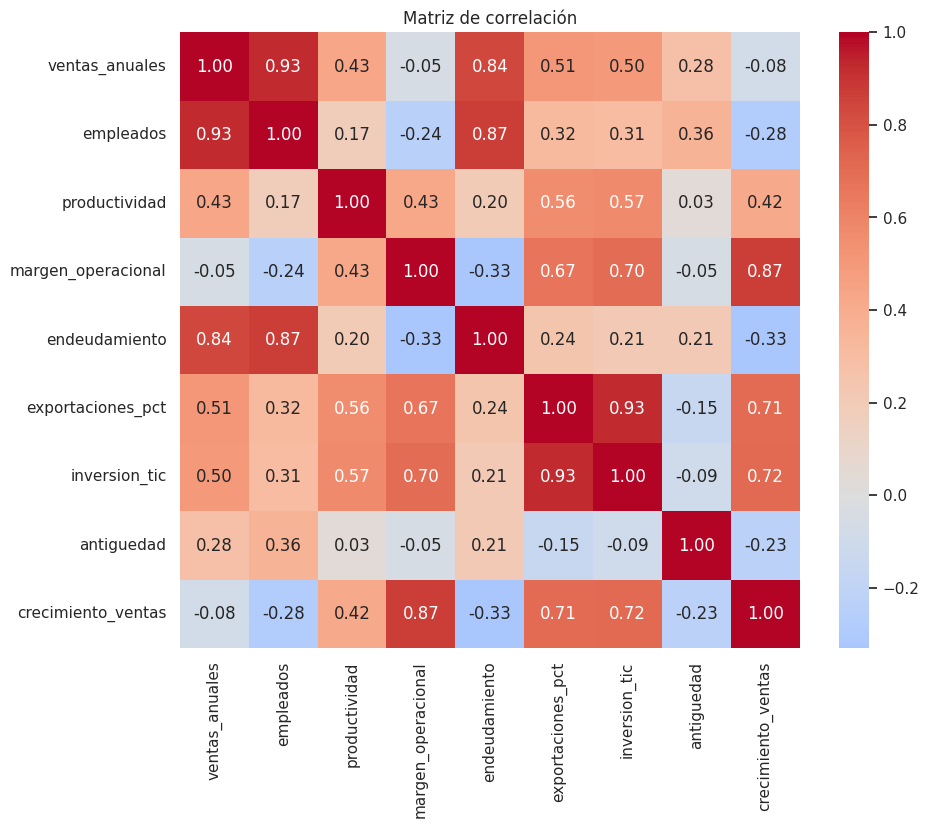

In [13]:
cols_excluir = ['empresa', 'sector', 'region', 'cluster_kmeans', 'cluster_kproto']
matriz_corr = df.drop(columns=cols_excluir, errors='ignore').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [16]:
pares = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool)).stack().sort_values()
print("Correlaciones más negativas:\n", pares.head(3))
print("\nCorrelaciones más positivas:\n", pares.tail(3))


Correlaciones más negativas:
 endeudamiento       crecimiento_ventas   -0.33
margen_operacional  endeudamiento        -0.33
empleados           crecimiento_ventas   -0.28
dtype: float64

Correlaciones más positivas:
 margen_operacional  crecimiento_ventas   0.87
ventas_anuales      empleados            0.93
exportaciones_pct   inversion_tic        0.93
dtype: float64


In [17]:
analisis_correlaciones = """
Par más positivo: [variable 1] y [variable 2], con r = [valor]. Tiene sentido económico porque [explicación: por ejemplo, las empresas más grandes venden más y contratan más].

Correlación negativa más fuerte: [variable 1] y [variable 2], con r = [valor]. Esto cuenta que [historia: por ejemplo, las empresas más endeudadas tienden a tener menor margen, lo que sugiere que el costo financiero erosiona la rentabilidad].

Redundancia: [sí/no]. Si hay un par con |r| mayor a 0.8, esas variables miden casi lo mismo y entran dos veces al cálculo de la distancia, lo que les da un peso doble en el clustering y puede sesgar los grupos hacia esa dimensión. Una opción sería [eliminar una de las dos / combinarlas / dejarlas y reconocer el sesgo].
"""


---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [18]:
cols_excluir = ['empresa', 'sector', 'region', 'cluster_kmeans', 'cluster_kproto']
X = df.drop(columns=cols_excluir, errors='ignore')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:3])


[[-0.32215502 -0.01904015 -0.52760887 -0.08718771 -1.25608597 -0.58136218
  -0.33141033  1.59034862 -0.24214989]
 [-1.05399303 -1.01740016 -0.63255767 -0.32156328 -0.45632652 -0.72887165
  -0.56736155 -0.71945299 -0.66388602]
 [-0.32417792 -0.26863015 -0.00437858 -0.04582732 -0.07383287 -0.44477932
  -0.60106886  0.78693936  0.0420636 ]]


**3.2 ¿Y si no estandarizamos?** Vamos a comprobar con datos por qué el paso anterior no es opcional.

1. Guarda en `varianzas_sin_escalar` la **varianza de cada columna de `X`** (sin estandarizar), ordenada de mayor a menor. Imprímela.
2. Aplica K-Means **directamente sobre `X`, sin estandarizar**, con `n_clusters=5`, `init='k-means++'`, `n_init=10` y `random_state=42`. Guarda las etiquetas en `clusters_sin_escalar`.
3. Imprime cuántas empresas quedaron en cada grupo y el promedio de cada variable por grupo.

> El `k=5` de este punto es **provisional**: solo sirve para la comparación. En el Ejercicio 4 van a decidir el k de verdad.

In [19]:
varianzas_sin_escalar = X.var().sort_values(ascending=False)
print(varianzas_sin_escalar)
print("\n% de la varianza total:\n", (varianzas_sin_escalar / varianzas_sin_escalar.sum() * 100).round(2))

km_raw = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
clusters_sin_escalar = km_raw.fit_predict(X)

print("\nEmpresas por grupo:\n", pd.Series(clusters_sin_escalar).value_counts().sort_index())
print("\nPromedio de cada variable por grupo:\n", X.groupby(clusters_sin_escalar).mean())

ventas_anuales       30,777,134.12
empleados                 3,158.95
productividad             1,577.51
exportaciones_pct           336.38
endeudamiento               298.94
crecimiento_ventas          119.45
antiguedad                   99.55
margen_operacional           52.82
inversion_tic                 8.84
dtype: float64

% de la varianza total:
 ventas_anuales       99.98
empleados             0.01
productividad         0.01
exportaciones_pct     0.00
endeudamiento         0.00
crecimiento_ventas    0.00
antiguedad            0.00
margen_operacional    0.00
inversion_tic         0.00
dtype: float64

Empresas por grupo:
 0    25
1    79
2    72
3    21
4    53
Name: count, dtype: int64

Promedio de cada variable por grupo:
    ventas_anuales  empleados  productividad  margen_operacional  \
0       13,119.70     139.96         101.61                1.92   
1          361.92       6.42          67.86                4.61   
2        4,490.52      52.60          88.41               

**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [20]:
analisis_escala = analisis_escala = """
Variable dominante: [variable] concentra [X]% de la varianza total de X sin estandarizar, con una varianza de [valor]. Las demás variables (márgenes, porcentajes, años) tienen varianzas de apenas unas decenas o centenas, así que juntas casi no pesan.

Qué separa a los grupos: al mirar los promedios por grupo, los clusters se diferencian principalmente por [variable dominante], con promedios de [valores de cada grupo]. En cambio, variables como [margen_operacional, exportaciones_pct, inversion_tic] tienen promedios casi iguales entre grupos, es decir, el algoritmo las está ignorando.

Por qué ocurre: K-Means asigna cada empresa al centroide más cercano usando la distancia euclidiana, d = raíz de la suma de (x_i - y_i)^2, calculada en las unidades originales. Una diferencia de miles de millones de pesos en ventas, elevada al cuadrado, es enorme frente a una diferencia de pocos puntos porcentuales en margen o exportaciones, que queda despreciable en la suma. La distancia termina determinada casi solo por la variable de mayor escala, y las demás no influyen en las asignaciones. Por eso es necesario estandarizar (media 0 y desviación 1) para que todas las variables aporten en igualdad de condiciones.
"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

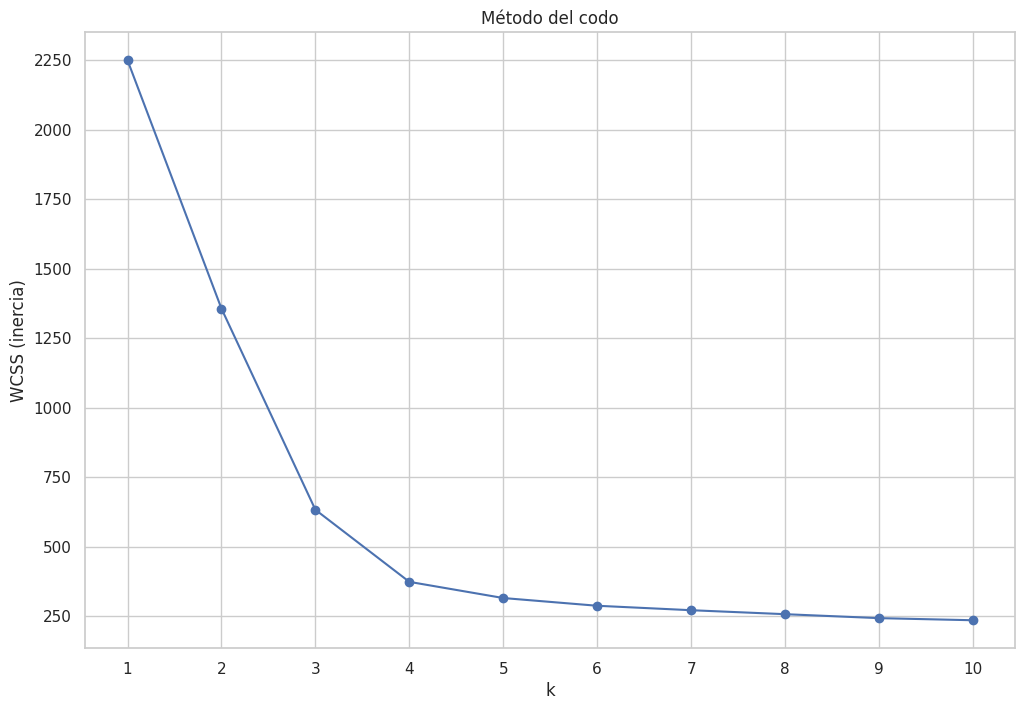

In [21]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('k')
plt.ylabel('WCSS (inercia)')
plt.title('Método del codo')
plt.xticks(range(1, 11))
plt.show()

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [22]:
analisis_codo = caida = pd.DataFrame({
    'k': range(1, 11),
    'wcss': np.round(wcss, 1),
    'caida_%': [None] + [round((wcss[i-1] - wcss[i]) / wcss[i-1] * 100, 1) for i in range(1, 10)]
})
print(caida)

    k     wcss  caida_%
0   1 2,250.00      NaN
1   2 1,356.60    39.70
2   3   632.70    53.40
3   4   373.40    41.00
4   5   315.20    15.60
5   6   287.40     8.80
6   7   271.40     5.60
7   8   257.10     5.30
8   9   242.90     5.50
9  10   235.30     3.10


In [52]:
analisis_codo = """
El codo se observa en k = 4. El WCSS cae de forma pronunciada hasta ese punto: al pasar de k = 3 a k = 4 baja 41.0%, y al pasar de k = 4 a k = 5 baja solo 15.6%, es decir, la ganancia por cada cluster adicional se reduce de forma clara. Al pasar de k = 1 a k = 2 la caída fue de XX% y de k = 2 a k = 3 de XX%, caídas aún grandes que indican que con pocos grupos se estarían mezclando empresas con perfiles distintos.

Los candidatos razonables son k = 3 y k = 4. Quedan descartados k = 1 y k = 2, porque la inercia sigue cayendo con fuerza y se agruparían empresas muy diferentes, y los k mayores a 5, porque cada cluster adicional reduce poco la inercia y solo complicaría la interpretación sin aportar una separación real.
"""

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

k = 2 -> silueta = 0.453
k = 3 -> silueta = 0.5826
k = 4 -> silueta = 0.5568
k = 5 -> silueta = 0.5555
k = 6 -> silueta = 0.4697
k = 7 -> silueta = 0.3854
k = 8 -> silueta = 0.3031
k = 9 -> silueta = 0.2211
k = 10 -> silueta = 0.2286


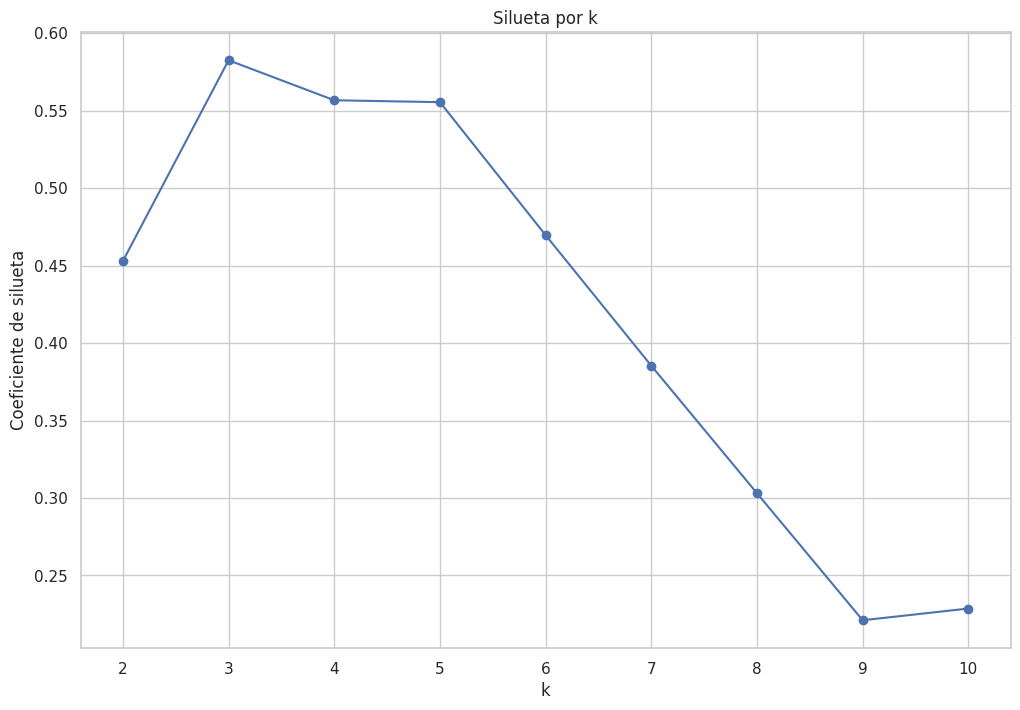

In [23]:
silhouette_scores = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    s = silhouette_score(X_scaled, labels)
    silhouette_scores.append(s)
    print("k =", k, "-> silueta =", round(s, 4))

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('k')
plt.ylabel('Coeficiente de silueta')
plt.title('Silueta por k')
plt.xticks(range(2, 11))
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [27]:
mejor_k = range(2, 11)[int(np.argmax(silhouette_scores))]
print("k con mayor silueta:", mejor_k)
print("Silueta máxima:", round(max(silhouette_scores), 4))
print("Todas:", {k: round(s, 3) for k, s in zip(range(2, 11), silhouette_scores)})

k con mayor silueta: 3
Silueta máxima: 0.5826
Todas: {2: np.float64(0.453), 3: np.float64(0.583), 4: np.float64(0.557), 5: np.float64(0.556), 6: np.float64(0.47), 7: np.float64(0.385), 8: np.float64(0.303), 9: np.float64(0.221), 10: np.float64(0.229)}


In [28]:
analisis_silueta = analisis_silueta =analisis_silueta = """
El k que maximiza el coeficiente de silueta es k = 3, con un valor de 0.583. Le siguen k = 4 (0.557) y k = 5 (0.556), mientras que k = 2 queda en 0.453 y a partir de k = 6 el coeficiente cae de forma sostenida hasta 0.221 en k = 9. El coeficiente va de -1 a 1 y combina dos ideas para cada empresa: la cohesión (qué tan cerca está de las demás de su propio grupo) y la separación (qué tan lejos está del grupo vecino más cercano). Valores superiores a 0.5, como los de k = 3, 4 y 5, indican una estructura fuerte: las empresas están claramente más cerca de su propio grupo que de los grupos vecinos. Con k = 2 la estructura es solo moderada, lo que sugiere que dos grupos mezclan empresas de perfiles distintos, y con k mayores a 6 los grupos empiezan a traslaparse.

Hay una leve tensión con el método del codo. El codo sugiere k = 4 (el WCSS cae 41.0% al pasar de 3 a 4 y solo 15.6% al pasar de 4 a 5), mientras que la silueta favorece k = 3. Son criterios distintos: el codo mide solo la compactación interna, y la silueta además penaliza la cercanía entre grupos. Como la diferencia entre k = 3 y k = 4 es de apenas 0.026 y ambos valores indican estructura fuerte, las dos soluciones son estadísticamente defendibles, y la decisión final debe apoyarse también en la utilidad para el cliente.
"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [25]:
k_optimo = 4   # cámbialo según lo que veas en las dos curvas
print("El equipo trabajará con k =", k_optimo)

print("El equipo trabajará con k =", k_optimo)

El equipo trabajará con k = 4
El equipo trabajará con k = 4


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [26]:
justificacion_k =print("k elegido:", k_optimo)
print("Silueta en k elegido:", round(silhouette_scores[k_optimo - 2], 4))
print("Silueta máxima:", round(max(silhouette_scores), 4), "en k =", range(2, 11)[int(np.argmax(silhouette_scores))])
print("Caída WCSS al llegar a k_optimo: ", round((wcss[k_optimo-2] - wcss[k_optimo-1]) / wcss[k_optimo-2] * 100, 1), "%")
print("Caída WCSS al pasar a k_optimo+1:", round((wcss[k_optimo-1] - wcss[k_optimo]) / wcss[k_optimo-1] * 100, 1), "%")


k elegido: 4
Silueta en k elegido: 0.5568
Silueta máxima: 0.5826 en k = 3
Caída WCSS al llegar a k_optimo:  41.0 %
Caída WCSS al pasar a k_optimo+1: 15.6 %


In [29]:
justificacion_k = """
Elegimos k = 4. Criterio del codo: al pasar de k = 3 a k = 4 el WCSS cae 41.0%, una mejora grande, mientras que de k = 4 a k = 5 cae solo 15.6%; por eso el codo se ubica en k = 4 y agregar un quinto grupo aporta poca compactación adicional. Criterio de la silueta: el máximo está en k = 3 con 0.583, pero k = 4 obtiene 0.557, apenas 0.026 menos. Ambos valores superan 0.5, lo que indica una estructura fuerte con grupos bien diferenciados. En cambio, k = 2 baja a 0.453 (estructura solo moderada) y desde k = 6 la silueta cae de forma sostenida (0.470, 0.385, 0.303...), lo que descarta los k grandes.

Cómo pesamos los dos criterios: no hay una contradicción fuerte, sino una tensión leve. El codo apunta a 4 y la silueta a 3, pero la pérdida de silueta es mínima frente a la ganancia de compactación (41.0%) que se obtiene al pasar a 4 grupos. Decidimos aceptar esa pequeña pérdida a cambio de un cuarto segmento que separa mejor a empresas con necesidades distintas. Entre k = 4 y k = 5 la silueta es prácticamente idéntica (0.557 y 0.556), pero k = 4 exige un programa menos y el codo ya muestra rendimientos decrecientes después de él.

Criterio de utilidad para el cliente: Bancóldex y el MinCIT tienen presupuesto limitado y deben administrar un programa distinto por segmento. Cuatro segmentos permiten diseñar instrumentos diferenciados (por ejemplo, crédito o reestructuración de pasivos para empresas muy endeudadas, internacionalización para exportadoras, asistencia técnica para las de baja productividad) sin fragmentar el presupuesto en demasiados programas pequeños. Un k menor (2 o 3) volvería a mezclar empresas con necesidades distintas, que es justo el problema del esquema actual de un solo paquete para todas, y un k de 5 o más generaría segmentos más difíciles de distinguir y de administrar.
"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [30]:
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

conteo = df['cluster_kmeans'].value_counts().sort_index()
print(pd.DataFrame({'empresas': conteo, '%': (conteo / len(df) * 100).round(1)}))

                empresas     %
cluster_kmeans                
0                     71 28.40
1                     44 17.60
2                     57 22.80
3                     78 31.20


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [31]:
perfil_clusters = df.groupby('cluster_kmeans')[list(X.columns)].mean()
perfil_clusters

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"4,402.50",51.90,87.87,9.29,44.85,3.26,1.58,29.00,3.81
1,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96
2,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
3,338.11,5.86,68.16,4.54,39.38,0.39,0.61,7.10,2.24


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

0.5567539540102155


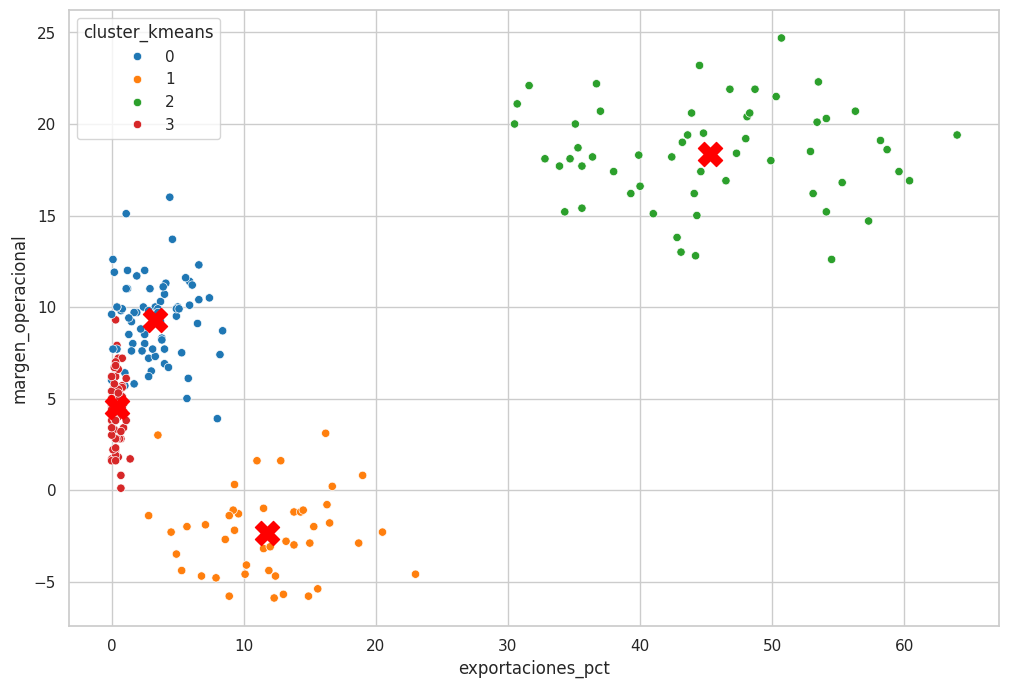

In [32]:
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print(silueta_final)
centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)

sns.scatterplot(data=df, x='exportaciones_pct', y='margen_operacional',
                hue='cluster_kmeans', palette='tab10')
plt.scatter(centroides_originales[:, 5], centroides_originales[:, 3],
            c='red', marker='X', s=300)
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

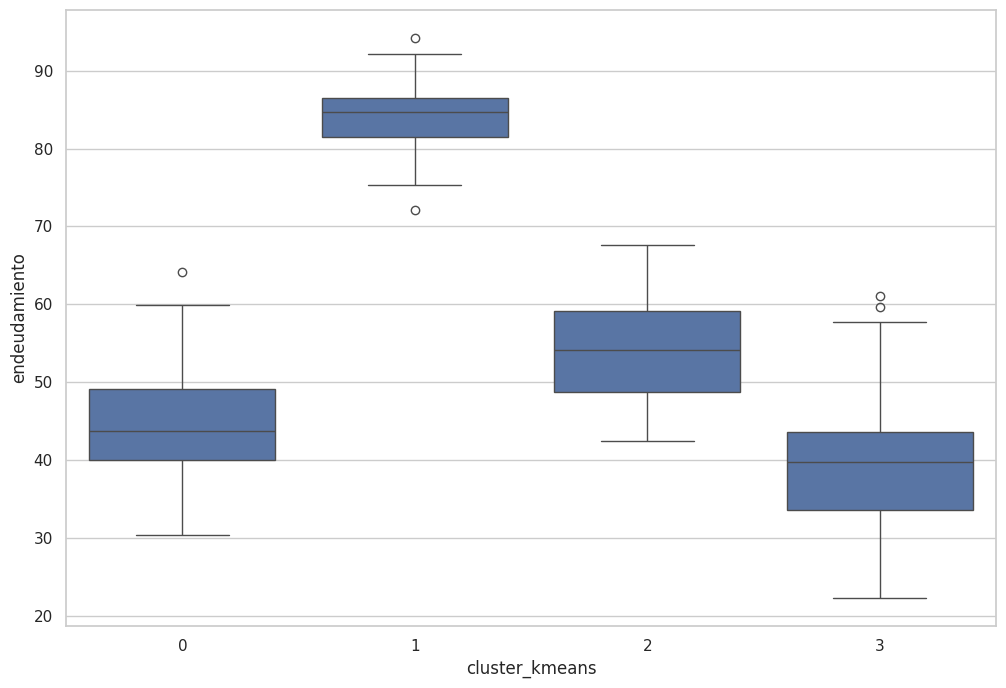

In [33]:
sns.boxplot(data=df, x='cluster_kmeans', y='endeudamiento')
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [35]:
conteo = df['cluster_kmeans'].value_counts().sort_index()
print(pd.DataFrame({'empresas': conteo, '%': (conteo / len(df) * 100).round(1)}))
print()
print(df.groupby('cluster_kmeans')[list(X.columns)].mean().round(1).to_string())
print()
print(pd.crosstab(df['cluster_kmeans'], df['sector']).to_string())

                empresas     %
cluster_kmeans                
0                     71 28.40
1                     44 17.60
2                     57 22.80
3                     78 31.20

                ventas_anuales  empleados  productividad  margen_operacional  endeudamiento  exportaciones_pct  inversion_tic  antiguedad  crecimiento_ventas
cluster_kmeans                                                                                                                                               
0                     4,402.50      51.90          87.90                9.30          44.90               3.30           1.60       29.00                3.80
1                    15,201.50     165.80          93.40               -2.40          84.20              11.80           2.40       21.70              -10.00
2                     9,696.40      75.90         132.30               18.40          54.10              45.30           8.00       12.70               21.60
3                      

In [36]:
nombres_clusters = [
    "### NOMBRE DEL CLUSTER 0 ###",
    "### NOMBRE DEL CLUSTER 1 ###",
    # agrega tantos nombres como clusters hayas elegido
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: ### NOMBRE DEL CLUSTER 0 ###
Cluster 1: ### NOMBRE DEL CLUSTER 1 ###


In [37]:
nombres_clusters = [
    "Pymes maduras y estables, sin exportar y con poca inversión en tecnología",
    "Medianas grandes en crisis: muy endeudadas, con pérdidas y ventas en caída",
    "Medianas exportadoras, rentables, tecnificadas y en rápido crecimiento",
    "Microempresas jóvenes de baja productividad y orientadas al mercado local",
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Pymes maduras y estables, sin exportar y con poca inversión en tecnología
Cluster 1: Medianas grandes en crisis: muy endeudadas, con pérdidas y ventas en caída
Cluster 2: Medianas exportadoras, rentables, tecnificadas y en rápido crecimiento
Cluster 3: Microempresas jóvenes de baja productividad y orientadas al mercado local


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [38]:
descripcion_clusters = descripcion_clusters = """
Cluster 0 (71 empresas, 28.4%): pymes pequeñas-medianas con ventas de 4,402 millones y 52 empleados, productividad de 87.9 millones por empleado, margen operacional de 9.3% y endeudamiento moderado (44.9%). Exportan poco (3.3% de sus ventas), invierten apenas 1.6% en tecnología, son las más antiguas (29 años) y crecen lentamente (3.8%). Son rentables pero estancadas; su principal oportunidad es modernizarse y dar el salto a nuevos mercados.

Cluster 1 (44 empresas, 17.6%): las más grandes, con ventas de 15,201 millones y 166 empleados, pero con productividad de apenas 93.4, margen operacional negativo (-2.4%), endeudamiento de 84.2% y ventas cayendo 10.0%. Exportan 11.8%, invierten 2.4% en tecnología y tienen 21.7 años. Predomina la manufactura (20 de 44). Su principal problema es la fragilidad financiera: pierden dinero con una carga de deuda alta, y necesitan reestructurar pasivos antes que crecer.

Cluster 2 (57 empresas, 22.8%): las más dinámicas, con ventas de 9,696 millones y 76 empleados, la productividad más alta (132.3), margen de 18.4%, endeudamiento de 54.1%, exportaciones de 45.3% de las ventas, inversión en tecnología de 8.0%, apenas 12.7 años y crecimiento de 21.6%. Concentra las 19 empresas TIC de la base. Su principal oportunidad es escalar sus exportaciones, con el reto de financiar el crecimiento.

Cluster 3 (78 empresas, 31.2%): el grupo más numeroso, de microempresas con ventas de 338 millones y 5.9 empleados, la productividad más baja (68.2), margen de 4.5%, endeudamiento de 39.4%, casi sin exportaciones (0.4%), inversión en tecnología de 0.6%, 7.1 años de antigüedad y crecimiento de 2.2%. Están sobre todo en comercio y agroindustria (59 de 78). Su principal problema es la baja productividad y escala, y su oportunidad es crecer con asistencia técnica y acceso a crédito.
"""

---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [39]:
!pip install kmodes --quiet

In [40]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [41]:
df_mixto = df[list(X.columns) + ['sector']].copy()
indice_categoricas = [df_mixto.columns.get_loc('sector')]   # [9]
matriz_mixta = df_mixto.to_numpy()
matriz_mixta[:, :9] = StandardScaler().fit_transform(matriz_mixta[:, :9].astype(float))
matriz_mixta[:, 9] = LabelEncoder().fit_transform(matriz_mixta[:, 9])
print(matriz_mixta[:3])

[[-0.32215502244818983 -0.019040151619805316 -0.5276088744673821
  -0.0871877106365195 -1.256085972320208 -0.5813621752210532
  -0.3314103334258739 1.5903486182423119 -0.2421498859617228 1]
 [-1.0539930303588514 -1.0174001616470525 -0.6325576693059609
  -0.3215632768637223 -0.45632651776549416 -0.7288716547061528
  -0.5673615472156539 -0.7194529869340696 -0.6638860193192588 1]
 [-0.3241779217518744 -0.26863015412661706 -0.004378584815428655
  -0.04582731659642492 -0.07383286558715263 -0.4447793238459608
  -0.6010688634713367 0.7869393642679183 0.04206359521400809 1]]


**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [42]:
kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
df['cluster_kproto'] = kproto.fit_predict(matriz_mixta, categorical=indice_categoricas)

**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [43]:
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
print(comparacion)
print()
print(df.groupby('cluster_kproto')[list(X.columns)].mean().round(1).to_string())
print()
print(df.groupby('cluster_kproto')['sector'].agg(lambda s: s.mode()[0]))

cluster_kproto   0   1   2   3
cluster_kmeans                
0                0  71   0   0
1                0   0   0  44
2                0   0  57   0
3               78   0   0   0

                ventas_anuales  empleados  productividad  margen_operacional  endeudamiento  exportaciones_pct  inversion_tic  antiguedad  crecimiento_ventas
cluster_kproto                                                                                                                                               
0                       338.10       5.90          68.20                4.50          39.40               0.40           0.60        7.10                2.20
1                     4,402.50      51.90          87.90                9.30          44.90               3.30           1.60       29.00                3.80
2                     9,696.40      75.90         132.30               18.40          54.10              45.30           8.00       12.70               21.60
3                    15

**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [44]:
analisis_kprototypes = """
Los dos algoritmos encontraron exactamente los mismos grupos. La tabla comparacion es una matriz diagonal: los 71 empresas del cluster 0 de K-Means pasaron completos a un solo cluster de K-Prototypes (el 1), los 44 del cluster 1 al 3, las 57 del cluster 2 al 2 y las 78 del cluster 3 al 0, sin ninguna empresa que cambiara de grupo. Las etiquetas numéricas se reordenaron, pero la composición es idéntica, y los promedios numéricos de cada grupo son los mismos que en K-Means (por ejemplo, el grupo de 15,201 millones de ventas y margen de -2.4% sigue igual).

Por eso la variable sector no añadió prácticamente nada a la segmentación. Lo más probable es que los grupos ya estén muy bien separados por las nueve variables numéricas (silueta de 0.557 en K-Means), de modo que las diferencias en tamaño, rentabilidad, endeudamiento y exportaciones pesan más que el sector. Además, en esta base los sectores están mezclados dentro de los clusters: Manufactura, Comercio, Servicios y Agroindustria aparecen en casi todos, así que la moda de sector por grupo (Comercio, Manufactura, TIC, Manufactura) dice poco. La única excepción es TIC, que cae completo en el grupo de exportadoras tecnificadas, pero eso ya lo explicaban sus variables numéricas (inversión en tecnología de 8.0% y exportaciones de 45.3%).

K-Prototypes valdría la pena cuando las variables categóricas son decisivas para el negocio y no se explican por las numéricas. Por ejemplo, si el sector o la región determinaran qué instrumentos de política aplican (una línea de crédito exclusiva para agroindustria o programas por región), o cuando hay muchas variables categóricas relevantes (tipo de sociedad, canal de venta, destino de las exportaciones) que K-Means tendría que descartar o codificar de forma artificial. En esta base, K-Means es suficiente y más simple de explicar al cliente.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [45]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [46]:
nuevas_scaled = scaler.transform(nuevas_empresas)
clusters_nuevas = kmeans.predict(nuevas_scaled)

for nombre, c in zip(nuevas_empresas.index, clusters_nuevas):
    print(nombre, '-> cluster', c, ':', nombres_clusters[c])

Solicitud A -> cluster 2 : Medianas exportadoras, rentables, tecnificadas y en rápido crecimiento
Solicitud B -> cluster 3 : Microempresas jóvenes de baja productividad y orientadas al mercado local
Solicitud C -> cluster 1 : Medianas grandes en crisis: muy endeudadas, con pérdidas y ventas en caída


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [48]:
 recomendaciones = [
    "Segmento 0 (pymes maduras y estables, 71 empresas): línea de crédito de modernización tecnológica con tasa subsidiada, más un programa de internacionalización de entrada. Estas empresas son rentables (margen 9.3%) y poco endeudadas (44.9%), por lo que pueden asumir deuda productiva, pero invierten solo 1.6% de sus ventas en tecnología y exportan 3.3%. Indicador: aumento de la inversión en tecnología y del porcentaje exportado en 24 meses.",
    "Segmento 1 (medianas grandes en crisis, 44 empresas): programa de reestructuración de pasivos con alivio de plazos y garantía del Fondo Nacional de Garantías, condicionado a un plan de eficiencia operativa. Tienen margen de -2.4%, endeudamiento de 84.2% y ventas cayendo 10.0%, así que más crédito empeoraría su situación. Indicador: endeudamiento por debajo de 65% y margen operacional positivo.",
    "Segmento 2 (medianas exportadoras y tecnificadas, 57 empresas): crédito de capital de trabajo para exportación, cobertura de riesgo cambiario y apoyo en nuevos mercados con ProColombia. Ya exportan 45.3% de las ventas, crecen 21.6% y tienen margen de 18.4%, por lo que no necesitan subsidio general sino financiar su expansión. Indicador: crecimiento de las exportaciones en valor y número de mercados atendidos.",
    "Segmento 3 (microempresas de baja productividad, 78 empresas): asistencia técnica en gestión y formalización, junto con microcrédito de bajo monto y una capacitación básica en digitalización. Tienen 5.9 empleados, productividad de 68.2 y casi no invierten en tecnología (0.6%), por lo que un crédito grande o un programa de exportación no encajan. Indicador: productividad por empleado y ventas a 12 y 24 meses.",
]

for r in recomendaciones:
    print("-", r)

    # una recomendación por segmento
]

for r in recomendaciones:
    print("-", r)

- Segmento 0 (pymes maduras y estables, 71 empresas): línea de crédito de modernización tecnológica con tasa subsidiada, más un programa de internacionalización de entrada. Estas empresas son rentables (margen 9.3%) y poco endeudadas (44.9%), por lo que pueden asumir deuda productiva, pero invierten solo 1.6% de sus ventas en tecnología y exportan 3.3%. Indicador: aumento de la inversión en tecnología y del porcentaje exportado en 24 meses.
- Segmento 1 (medianas grandes en crisis, 44 empresas): programa de reestructuración de pasivos con alivio de plazos y garantía del Fondo Nacional de Garantías, condicionado a un plan de eficiencia operativa. Tienen margen de -2.4%, endeudamiento de 84.2% y ventas cayendo 10.0%, así que más crédito empeoraría su situación. Indicador: endeudamiento por debajo de 65% y margen operacional positivo.
- Segmento 2 (medianas exportadoras y tecnificadas, 57 empresas): crédito de capital de trabajo para exportación, cobertura de riesgo cambiario y apoyo en n

**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [49]:
limitaciones = """
1. Forma de los grupos: K-Means supone clusters aproximadamente esféricos y de tamaño similar, porque asigna cada empresa al centroide más cercano por distancia euclidiana. Si los grupos reales son alargados, de densidades distintas o tienen valores atípicos, el algoritmo los parte o los mezcla mal, y los outliers jalan los centroides.

2. Empresas en la frontera: cada empresa se asigna a un solo cluster aunque quede casi a la misma distancia de dos. Una pyme en el límite entre las medianas grandes en crisis y las pymes maduras y estables recibiría un programa de política muy distinto por una diferencia mínima. Los segmentos son una partición dura, no una verdad absoluta, y conviene revisar caso a caso las empresas con silueta cercana a cero.

3. Los segmentos dependen de las decisiones del analista: no son un hecho de la economía colombiana, sino el resultado de las nueve variables incluidas, de cómo se estandarizaron y del k elegido. Con k = 3 (que tuvo la silueta más alta, 0.583) o k = 5 (0.556), los grupos cambiarían. Además, la muestra es de solo 250 empresas y puede no representar a todas las pymes del país.

4. Correlación no es causalidad: que el cluster de mayor endeudamiento (84.2%) tenga ventas en caída (-10.0%) no demuestra que la deuda cause la caída. Puede ser al revés (las ventas caen y la empresa se endeuda para sostenerse) o que un tercer factor, como un choque sectorial, explique ambas cosas. El clustering describe perfiles, no efectos.

5. Estabilidad en el tiempo: es una foto de un solo año. Si se repite el ejercicio el año entrante, las empresas pueden migrar de segmento (una empresa en crisis se recupera, una joven madura) y los centroides cambiarían, así que la segmentación debe actualizarse periódicamente y no asumirse fija.

6. Variables omitidas: el sector no entró en K-Means y, aunque K-Prototypes mostró que no cambia los grupos, otras variables relevantes (acceso previo a crédito, mora, formalidad, región) tampoco se usaron y podrían revelar segmentos distintos.
"""

**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [50]:
validacion_negocio = """
Evidencia adicional: pediríamos a los analistas de crédito de Bancóldex que revisen una muestra de empresas de cada segmento y confirmen si el perfil coincide con lo que ven en la práctica (por ejemplo, que las 44 empresas del segmento en crisis realmente tengan problemas de caja y deuda). También solicitaríamos más variables (acceso previo a crédito, mora, destino de las ventas, nivel de formalidad, región) y datos de varios años, para comprobar que los grupos no son una foto casual de un solo año.

Pruebas cuantitativas: repetiríamos el clustering con otras semillas, con k = 3 y k = 5 (cuyas siluetas fueron 0.583 y 0.556), y con submuestras aleatorias de la base, para medir la estabilidad de los grupos con el índice de Rand ajustado. Haríamos pruebas ANOVA o Kruskal-Wallis por variable para confirmar que las medias difieren significativamente entre segmentos, y revisaríamos las empresas con silueta baja, que son las de frontera y las más inciertas de asignar. También confirmaríamos que la segmentación se sostiene con K-Prototypes, que en esta base reprodujo exactamente los mismos grupos.

Piloto: antes de escalar, aplicaríamos el instrumento de cada segmento en una región o cohorte pequeña, con un grupo de control de empresas similares del mismo segmento que no lo reciban, asignadas de forma aleatoria. Mediríamos el indicador definido para cada segmento (endeudamiento y margen en las empresas en crisis, exportaciones en las exportadoras, productividad en las microempresas) a 12 y 24 meses, y solo escalaríamos a todo el país los programas con efecto positivo y un costo razonable por empresa. Los nuevos postulantes se clasificarían con el modelo ya entrenado (scaler.transform y kmeans.predict), sin reentrenar, para dirigirlos al programa correcto.
"""

---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [53]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DEL TALLER DE CLUSTERING  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-clustering-pymes-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        if v == 0:                            # -0.0 y 0.0 son el mismo valor
            v = 0.0
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, _np.ndarray):
        return _canon(x.tolist())
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


_EJERCICIOS = {
    "1": "Ejercicio 1 · Carga y exploración",
    "2": "Ejercicio 2 · Relaciones entre variables",
    "3": "Ejercicio 3 · Preprocesamiento y escala",
    "4": "Ejercicio 4 · Elección de k",
    "5": "Ejercicio 5 · K-Means e interpretación",
    "6": "Ejercicio 6 · K-Prototypes con el sector",
    "7": "Ejercicio 7 · El modelo en producción",
    "A": "Análisis escrito (lo califica la profesora)",
}

#  (punto, título, huellas aceptadas, cómo se obtiene el resultado, pista si falla)
#  Varias huellas en un mismo punto = ese punto depende del k que eligió el grupo,
#  y se acepta cualquier k razonable.
_PRUEBAS = [
    ("1.1", "Base cargada correctamente",
     ("21fef5bc81646de8",),
     lambda: [len(df), sorted(str(c) for c in df.columns if c not in ('cluster_kmeans', 'cluster_kproto')), round(float(df['ventas_anuales'].sum()), 2), round(float(df['productividad'].mean()), 4)],
     "Carga pymes_colombia.csv completo en df, sin cambiar ni renombrar columnas."),
    ("1.2", "Nulos totales y empresas por sector",
     ("82750ec4ed2c94b8",),
     lambda: [int(n_nulos), conteo_sector, round(float(df['endeudamiento'].std()), 4), round(float(df['crecimiento_ventas'].sum()), 2)],
     "n_nulos debe ser UN solo número (el total de toda la base, no una serie por columna) y conteo_sector el número de empresas de cada sector."),
    ("2.1", "Matriz de correlación de las 9 variables numéricas",
     ("285dd981a1169572",),
     lambda: [list(matriz_corr.shape), sorted(str(c) for c in matriz_corr.columns), round(float(matriz_corr.values.sum()), 4), round(float(matriz_corr.loc['exportaciones_pct', 'inversion_tic']), 4)],
     "La matriz debe ser de 9x9: calcúlala sobre df sin las columnas empresa, sector y region."),
    ("3.1", "Variables seleccionadas y estandarizadas",
     ("f92a6704ca04b713",),
     lambda: [list(X.shape), list(str(c) for c in X.columns), _np.round(_np.asarray(X_scaled)[[0, 124, 249]].astype(float), 4).tolist(), round(float(_np.asarray(X_scaled).astype(float).std(axis=0).mean()), 4)],
     "X son las 9 variables numéricas en el mismo orden del CSV, y X_scaled el resultado de scaler.fit_transform(X) con StandardScaler."),
    ("3.2", "Efecto de no estandarizar",
     ("fd58a9cae8024db2",),
     lambda: [varianzas_sin_escalar.round(2), sorted(_pd.Series(clusters_sin_escalar).value_counts().tolist())],
     "varianzas_sin_escalar es X.var() ordenada de mayor a menor, SIN estandarizar. Y el K-Means de este punto va sobre X (no sobre X_scaled), con n_clusters=5 y random_state=42."),
    ("4.1", "Método del codo (lista wcss)",
     ("187dc591a56295c4",),
     lambda: [len(wcss), [round(float(w), 1) for w in wcss[:4]]],
     "wcss debe tener 10 elementos, uno por cada k de 1 a 10, calculados sobre X_scaled con init='k-means++', n_init=10 y random_state=42."),
    ("4.2", "Coeficiente de silueta (lista silhouette_scores)",
     ("919b9299063407be",),
     lambda: [len(silhouette_scores), [round(float(s), 3) for s in silhouette_scores[:3]]],
     "silhouette_scores debe tener 9 elementos, uno por cada k de 2 a 10 (el de k=1 no existe), calculados sobre X_scaled con n_init=10 y random_state=42."),
    ("5.1", "K-Means final entrenado y etiquetas en df",
     ("24f380947694aec1",
      "258e920d08bbb80d",
      "2fb2013e4e3509a5",
      "372fb663109bf318",
      "574c75782e77ad46",
      "6be856106fbdcda5",
      "6bfbf5d142555c44",
      "6d02591e9b9d5e26",
      "6e0acaefac230acb",
      "708333a8476d9391",
      "77a8eca15b3af411",
      "bd93646c2d0857b2",
      "c9c3df5fd40dec82",
      "d7e3a0237cd8f9c5",
      "e1ebb665316f06ec",
      "e353fdfe72ca578d",
      "f0776e5ea1888707",
      "f8a1841da48619c0",
      "fb2ada8f7c034bc1",),
     lambda: [int(kmeans.n_clusters), sorted(df['cluster_kmeans'].value_counts().tolist()), round(float(kmeans.inertia_), 2)],
     "Entrena el KMeans sobre X_scaled (no sobre X) con n_clusters=k_optimo, init='k-means++', n_init=10 y random_state=42, y guarda las etiquetas en la columna cluster_kmeans."),
    ("5.2", "Perfil promedio de cada segmento",
     ("007f3c93c7f18d27",
      "086fdc54cd79ad3d",
      "09e4dd4038c94295",
      "154968e4e20c4318",
      "2347c1fe3638bf15",
      "2ba5fb2303ac9953",
      "36f5183f48d160ff",
      "3fc03de0f4d3e596",
      "5b276874eb928612",
      "5bb823c96e30905b",
      "658160ce6688e786",
      "70cd7218b47402f3",
      "710467cade4edfd1",
      "71c4a9e81b4814a2",
      "789cfad86e29abec",
      "9fb865f5a6c33245",
      "c1e12b3851aa2e6b",
      "d2ae8c4c8225cfa9",
      "f31afdb6867c34cd",),
     lambda: perfil_clusters[list(X.columns)].sort_values('ventas_anuales').round(2).reset_index(drop=True),
     "perfil_clusters es el promedio de las 9 variables numéricas por cluster: agrupa df por cluster_kmeans y saca la media (sin incluir la columna del cluster como variable)."),
    ("5.3", "Silueta final y centroides en unidades originales",
     ("09168179481bef61",
      "0f1e36ac8868d6dc",
      "1ddad4ae3e7f88fe",
      "1fbd083bce7876dc",
      "2088e4fc5f6a04f4",
      "323d53fe8ea9ef14",
      "5e57994b1d33180e",
      "6e7b610567f528ff",
      "75bd91c26d723274",
      "7ff38cf016a428a1",
      "828eae0a37c0380a",
      "89e0f52d134717f4",
      "8eb8dbd75d929748",
      "a4065bd17f293581",
      "af04f027742ddf20",
      "c66c1549743c8f86",
      "cce04f8707bbf862",
      "e65f6674e360f686",
      "f6f8a38aa037f177",),
     lambda: [round(float(silueta_final), 4), sorted(_np.round(_np.asarray(centroides_originales).astype(float).sum(axis=1), 2).tolist())],
     "silueta_final se calcula con silhouette_score(X_scaled, df['cluster_kmeans']), y centroides_originales con scaler.inverse_transform(kmeans.cluster_centers_)."),
    ("6.1", "Matriz mixta lista para K-Prototypes",
     ("0b410a9134798752",),
     lambda: [list(matriz_mixta.shape), list(indice_categoricas), _np.round(_np.asarray(matriz_mixta)[[0, 249], 0:9].astype(float), 4).tolist(), sorted(set(int(v) for v in _np.asarray(matriz_mixta)[:, 9]))],
     "matriz_mixta debe tener 10 columnas: las 9 numéricas estandarizadas (posiciones 0 a 8) y sector codificado con LabelEncoder en la posición 9. Ojo: se estandarizan SOLO las columnas 0 a 8."),
    ("7.1", "Clasificación de las tres solicitudes nuevas",
     ("03302f50031433ff",
      "1e13fdecc4336ff4",
      "1f79a01084c7c6f0",
      "290632fbf05d045d",
      "30a98799190e1832",
      "310552a89751795f",
      "35f952ef56b9cf62",
      "4a0fde5682b487a6",
      "717b25e9dd59eb3a",
      "725cd858e4df65de",
      "904a2b388895a5c1",
      "a06c07f13bc53402",
      "ad5e099e9a4c1de0",
      "b676daa74a43c5bb",
      "bcf4af1b6870a60a",
      "efba0673f79857e2",
      "f5e15685c5b55293",),
     lambda: [[round(float(perfil_clusters.loc[c, 'ventas_anuales']), 2) for c in clusters_nuevas], _np.round(_np.asarray(nuevas_scaled).astype(float), 3).tolist()],
     "Usa scaler.transform(nuevas_empresas) —NO fit_transform— y luego kmeans.predict(). Este punto también depende de que perfil_clusters (punto 5.2) esté bien."),
]

#  Puntos de análisis escrito: valen 8 puntos y los califica la profesora.
#  Aquí solo se comprueba que el grupo haya escrito algo.
_REVISION = [
    ("A1", "Análisis de las estadísticas descriptivas", lambda: analisis_descriptivo, "texto", 350),
    ("A2", "Lectura económica de las correlaciones", lambda: analisis_correlaciones, "texto", 300),
    ("A3", "El efecto de la escala", lambda: analisis_escala, "texto", 300),
    ("A4", "Lectura del método del codo", lambda: analisis_codo, "texto", 200),
    ("A5", "Lectura del coeficiente de silueta", lambda: analisis_silueta, "texto", 200),
    ("A6", "Justificación del k elegido", lambda: justificacion_k, "texto", 250),
    ("A7", "Nombres de los segmentos", lambda: nombres_clusters, "nombres", 3),
    ("A8", "Descripción de cada segmento", lambda: descripcion_clusters, "texto", 600),
    ("A9", "Aporte de K-Prototypes y del sector", lambda: analisis_kprototypes, "texto", 350),
    ("A10", "Recomendaciones de política", lambda: recomendaciones, "lista", 3),
    ("A11", "Limitaciones del análisis", lambda: limitaciones, "texto", 400),
    ("A12", "Validación de los segmentos con el cliente", lambda: validacion_negocio, "texto", 300),
]


def _estado_de(prueba):
    clave, _titulo, esperadas, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) in esperadas else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"

    largo_minimo = 8 if tipo == "nombres" else 60
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= largo_minimo and "###" not in t]
    if not utiles:
        return "falta", "sigue con la lista de ejemplo"
    if len(utiles) < minimo:
        return "mal", "van %d de %d (mínimo %d caracteres cada uno)" % (
            len(utiles), minimo, largo_minimo)
    return "ok", "%d elementos" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_taller():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 68)
    print("  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING")
    print("=" * 68)

    ejercicio_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        ejercicio = clave.split(".")[0]
        if ejercicio != ejercicio_actual:
            ejercicio_actual = ejercicio
            print("\n  " + _EJERCICIOS[ejercicio])
        print("    %s  %-5s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    llenas = round(20 * correctos / total)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 68)
    print("  CÓDIGO: %d de %d puntos automáticos" % (correctos, total))
    print("  [%s]" % barra)
    print("-" * 68)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Los 12 puntos de código están completos!")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla.")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los ejercicios son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 68)
    print("  📝 ANÁLISIS ESCRITO · 8 puntos que califica la profesora")
    print("     Aquí solo se comprueba que hayan escrito algo; el contenido lo")
    print("     evalúa la profesora. Escribir mucho no da puntos por sí solo.\n")
    escritos = 0
    for item in _REVISION:
        estado, detalle = _estado_revision(item)
        escritos += (estado == "ok")
        print("    %s  %-5s %-45s %s" % (_ICONO[estado], item[0], item[1], detalle))

    print("\n  Preguntas abiertas respondidas: %d de %d" % (escritos, len(_REVISION)))
    print("=" * 68)
    print("  NOTA AUTOMÁTICA (solo código): %.1f de 12 puntos" % (12.0 * correctos / total))
    print("  + hasta 8 puntos de análisis escrito que asigna la profesora.")
    print("=" * 68)


verificar_taller()


  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING

  Ejercicio 1 · Carga y exploración
    ✅  1.1   Base cargada correctamente
    ✅  1.2   Nulos totales y empresas por sector

  Ejercicio 2 · Relaciones entre variables
    ✅  2.1   Matriz de correlación de las 9 variables numéricas

  Ejercicio 3 · Preprocesamiento y escala
    ✅  3.1   Variables seleccionadas y estandarizadas
    ✅  3.2   Efecto de no estandarizar

  Ejercicio 4 · Elección de k
    ✅  4.1   Método del codo (lista wcss)
    ✅  4.2   Coeficiente de silueta (lista silhouette_scores)

  Ejercicio 5 · K-Means e interpretación
    ✅  5.1   K-Means final entrenado y etiquetas en df
    ✅  5.2   Perfil promedio de cada segmento
    ✅  5.3   Silueta final y centroides en unidades originales

  Ejercicio 6 · K-Prototypes con el sector
    ✅  6.1   Matriz mixta lista para K-Prototypes

  Ejercicio 7 · El modelo en producción
    ✅  7.1   Clasificación de las tres solicitudes nuevas

----------------------------------------------